In [1]:
import sys, os, json, glob, io, contextlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

# ── Paths — edit these ────────────────────────────────────────────────────────
ROOT       = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/CDKL5_T1"
ANCHOR     = "AnalyzedData"
REF_EXCEL  = "/pscratch/sd/m/mpatil1/Data/CDKL5_T1/CDKL5_T1_C1_reff_new.xlsx"
FIGURE_DIR = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/CDKL5_T1/figures"
OUTPUT_CSV = os.path.join(FIGURE_DIR, "final_merged_mea_data.csv")

# ── Experiment config ─────────────────────────────────────────────────────────
GROUP_ORDER  = ['MxWT', 'FxHET', 'MxHEMI']
PALETTE      = {'MxWT': '#4C72B0', 'FxHET': '#D55E00', 'MxHEMI': '#A63226'}
ASSAY_FILTER = 'Network Today'

# Biologically motivated DIVs for stats (set None to test all DIVs in data)
SELECTED_DIVS = [8, 16, 23]

# Wells/DIVs to exclude: (ID, Well) removes all DIVs; (ID, Well, DIV) removes one
EXCLUDE      = [
    ('M07420', 'well005'),
    ('M07039', 'well004'),
    ('M07420', 'well002', 27),
    ('M07420', 'well004', 8),
]
EXCLUDE_DIVS = [5]

# Metrics as (column_name, y-axis label) — mirrors networkmetricsfigures.ipynb
METRICS = [
    ('nb_count',              'Network Burst Count'),
    ('nb_rate_hz',            'Network Burst Rate (Hz)'),
    ('nb_duration_mean',      'Mean Network Burst Duration (s)'),
    ('nb_ibi_mean',           'Mean Inter-Burst Interval (s)'),
    ('nb_spikes_mean',        'Mean Spikes per Network Burst'),
    ('nb_participation_mean', 'Mean Participation Fraction'),
    ('nb_burst_peak_mean',    'Mean Peak Population Firing Rate (Hz)'),
    ('nb_fragment_mean',      'Mean Fragment Count per Burst'),
    ('nb_peak_sync_mean',     'Mean Peak Participation Fraction'),
    ('bl_count',              'Burst Fragment Count'),
    ('bl_rate_hz',            'Burst Fragment Rate (Hz)'),
    ('bl_duration_mean',      'Mean Burst Fragment Duration (s)'),
    ('bl_participation_mean', 'Mean Burst Fragment Participation'),
    ('sb_count',              'Superburst Count'),
    ('sb_rate_hz',            'Superburst Rate (Hz)'),
    ('sb_duration_mean',      'Mean Superburst Duration (s)'),
    ('n_units',               'Number of Units'),
]

# ── Discover JSON files ───────────────────────────────────────────────────────
files = glob.glob(os.path.join(ROOT, "**", "*network*.json"), recursive=True)
df    = pd.DataFrame(files, columns=['full_path'])

def _parse_path(path):
    parts = path.split(os.sep)
    if ANCHOR in parts:
        i = parts.index(ANCHOR)
        try:
            return pd.Series([parts[i+1], parts[i+2], parts[i+3], parts[i+5], parts[i+6]])
        except IndexError:
            pass
    return pd.Series([None] * 5)

df[["Project", "Date", "Chip_ID", "RunID", "Well"]] = df['full_path'].apply(_parse_path)
df = df[["Project", "Date", "Chip_ID", "RunID", "Well", "full_path"]]

print(f"Found {len(df)} network JSON files.")

Found 389 network JSON files.


In [2]:
def extract_metrics(row):
    path = row['full_path']
    metrics = {}
    try:
        with open(path) as f:
            data = json.load(f)

        # Aggregate mean/std/cv keys renamed to the short names already used by
        # METRICS/LMM/FDR cells below (duration, ibi, spikes, participation,
        # burst_peak, peak_sync). burst_area keeps its JSON name — nothing
        # downstream reads it under the old (misleading) "intensity" alias.
        _AGG_RENAME = {
            "burst_duration_s":               "duration",
            "spike_count_per_burst":          "spikes",
            "participation_fraction":         "participation",
            "peak_population_firing_rate_hz": "burst_peak",
            "peak_participation_fraction":    "peak_sync",
        }

        def extract_block(block, prefix, ibi_key):
            if block is None:
                return
            m      = block.get("metrics", {})
            events = block.get("events", [])

            metrics[f"{prefix}_count"]   = m.get("burst_count", np.nan)
            metrics[f"{prefix}_rate_hz"] = m.get("burst_rate_hz", np.nan)

            # Aggregate mean/std/cv for every stats-dict metric the detector emits.
            for key, val in m.items():
                if key == ibi_key:
                    outkey = f"{prefix}_ibi"
                else:
                    outkey = f"{prefix}_{_AGG_RENAME.get(key, key)}"
                if isinstance(val, dict):
                    for stat in ("mean", "std", "cv"):
                        metrics[f"{outkey}_{stat}"] = val.get(stat)
                else:
                    metrics[outkey] = val

            # ── Per-event distributions ──────────────────────────────────────
            # Collect EVERY numeric field present on the events, named after
            # the JSON field itself (no relabeling) so there is no ambiguity
            # between e.g. spike_count and burst_area — each gets its own
            # {prefix}_{field}_list column. Covers burst_fragments (bl),
            # network_bursts (nb, incl. component_count/n_components from
            # merging), and superbursts (sb, same merge fields).
            if events:
                numeric_keys = sorted({
                    k for ev in events for k, v in ev.items()
                    if isinstance(v, (int, float)) and not isinstance(v, bool)
                })
                for k in numeric_keys:
                    metrics[f"{prefix}_{k}_list"] = [ev.get(k, np.nan) for ev in events]

                starts = [ev.get("start_time_s", np.nan) for ev in events]
                metrics[f"{prefix}_ibi_list"] = (
                    [float(x) for x in np.diff(starts)] if len(starts) > 1 else []
                )
            else:
                metrics[f"{prefix}_ibi_list"] = []

        # burst_fragments → bl, network_bursts → nb, superbursts → sb
        extract_block(data.get("burst_fragments"), "bl", "ifbi_s")
        extract_block(data.get("network_bursts"),  "nb", "ibi_s")
        extract_block(data.get("superbursts"),     "sb", "isbi_s")

        # Convenience alias used by the DIV trajectory / LMM cells below —
        # network_bursts' component_count *is* the fragment count per burst.
        if "nb_component_count_list" in metrics:
            metrics["nb_fragment_list"] = metrics["nb_component_count_list"]
            metrics["nb_fragment_mean"] = (
                float(np.mean(metrics["nb_fragment_list"])) if metrics["nb_fragment_list"] else np.nan
            )

        for k, v in (data.get("diagnostics") or {}).items():
            metrics[f"diag_{k}"] = v
        metrics["n_units"] = data.get("n_units", np.nan)

    except Exception as e:
        print(f"[ERROR] {path}: {e}")
    return pd.Series(metrics)

print("Extracting metrics from all JSON files…")
df_metrics = df.apply(extract_metrics, axis=1)
result_df  = pd.concat([df, df_metrics], axis=1)
print(f"Done — {len(result_df)} rows, {len(result_df.columns)} columns.")

Extracting metrics from all JSON files…
Done — 389 rows, 187 columns.


In [3]:
# ── Load reference metadata (chip / well / DIV / assay / genotype) ────────────
ref_df = pd.read_excel(REF_EXCEL)
ref_df['Wells_List']  = ref_df['Wells_Recorded'].astype(str).str.split(',')
ref_df['Source_List'] = ref_df['Neuron Source'].astype(str).str.split(',')
ref_df = ref_df.explode(['Wells_List', 'Source_List'])
ref_df['Well']       = 'well' + (ref_df['Wells_List'].str.strip().astype(int) - 1).astype(str).str.zfill(3)
ref_df['NeuronType'] = ref_df['Source_List'].str.strip()
ref_df = ref_df[['Date', 'ID', 'Run #', 'Well', 'NeuronType', 'Assay', 'DIV']].copy()

# ── Align types then merge ─────────────────────────────────────────────────────
result_df = result_df.rename(columns={"RunID": "Run #", "Chip_ID": "ID"})
result_df['Date']  = result_df['Date'].astype(str)
result_df['Run #'] = result_df['Run #'].astype(str).str.zfill(6)
ref_df['Run #']    = ref_df['Run #'].astype(str).str.zfill(6)

assert not result_df.duplicated(['ID', 'Date', 'Run #', 'Well']).any(), "Duplicate JSON rows"
assert not ref_df.duplicated(['ID', 'Date', 'Run #', 'Well']).any(),    "Duplicate ref rows"

merged_df = pd.merge(result_df, ref_df, how='left', on=['ID', 'Run #', 'Well'], validate='one_to_one')
merged_df.sort_values(['ID', 'Run #', 'Well'], inplace=True)

os.makedirs(FIGURE_DIR, exist_ok=True)
merged_df.to_csv(OUTPUT_CSV, index=False)
print(f"Merged {len(merged_df)} rows → {OUTPUT_CSV}")
merged_df.head()

Merged 389 rows → /pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/CDKL5_T1/figures/final_merged_mea_data.csv


,Project,Date_x,ID,Run #,Well,full_path,bl_burst_area_cv,bl_burst_area_list,bl_burst_area_mean,bl_burst_area_std,...,sb_spikes_per_burst_std,sb_spikes_std,sb_start_list,sb_start_time_s_list,sb_synchrony_energy_list,sb_total_spikes_list,Date_y,NeuronType,Assay,DIV
241,CDKL5_T1,240520,M07039,000006,well000,/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedDa...,0.620385,"[4.933616793817235, 5.239773901029653, 1.48917...",2.049184,1.271283,...,NaN,NaN,NaN,NaN,NaN,NaN,2024-05-20,MxHEMI,Network Today,5.0
244,CDKL5_T1,240520,M07039,000006,well001,/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedDa...,0.018887,"[4.672261840192887, 4.499040480624864]",4.585651,0.086611,...,NaN,NaN,NaN,NaN,NaN,NaN,2024-05-20,MxWT,Network Today,5.0
245,CDKL5_T1,240520,M07039,000006,well002,/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedDa...,0.537701,"[1.6719306346177574, 1.153549499239468, 2.2733...",2.755199,1.481474,...,NaN,NaN,NaN,NaN,NaN,NaN,2024-05-20,FxHET,Network Today,5.0
242,CDKL5_T1,240520,M07039,000006,well003,/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedDa...,0.717453,"[4.616804378499715, 1.4840869597364266, 2.3311...",1.969755,1.413208,...,NaN,NaN,NaN,NaN,NaN,NaN,2024-05-20,MxHEMI,Network Today,5.0
243,CDKL5_T1,240520,M07039,000006,well004,/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedDa...,0.916444,"[0.5344228353922014, 0.5411933217845095, 1.175...",0.591257,0.541853,...,NaN,168.302822,NaN,"[20.44092845943218, 57.573219294114864, 122.88...",NaN,NaN,2024-05-20,MxWT,Network Today,5.0


In [4]:
# ── Filter: assay type, excluded wells/DIVs ───────────────────────────────────
network_assay_df = merged_df[merged_df['Assay'] == ASSAY_FILTER].copy()

def _exclude_mask(df):
    mask = pd.Series(False, index=df.index)
    for item in EXCLUDE:
        if len(item) == 2:
            id_, well = item
            mask |= (df['ID'] == id_) & (df['Well'] == well)
        else:
            id_, well, div = item
            mask |= (df['ID'] == id_) & (df['Well'] == well) & (df['DIV'] == div)
    return mask

n_before = len(network_assay_df)
network_assay_df = network_assay_df[~_exclude_mask(network_assay_df)].copy()
network_assay_df = network_assay_df[~network_assay_df['DIV'].isin(EXCLUDE_DIVS)].copy()

# Unit identifier for LMM random effect (one trajectory per chip×well)
network_assay_df['CHIP_WELL'] = network_assay_df['ID'] + '_' + network_assay_df['Well']

if SELECTED_DIVS is None:
    SELECTED_DIVS = sorted(network_assay_df['DIV'].unique().tolist())

print(f"Removed {n_before - len(network_assay_df)} rows. Remaining: {len(network_assay_df)}")
print(f"DIVs (all): {sorted(network_assay_df['DIV'].unique().tolist())}")
print(f"DIVs (stats): {SELECTED_DIVS}")
print(f"Groups: {network_assay_df['NeuronType'].unique().tolist()}")

Removed 40 rows. Remaining: 152
DIVs (all): [8.0, 13.0, 16.0, 20.0, 23.0, 27.0, 30.0]
DIVs (stats): [8, 16, 23]
Groups: ['MxHEMI', 'MxWT', 'FxHET']


In [5]:
# ── Export distribution-list features for the ML classifier notebook ────────
# Each bl_/nb_/sb_ *_list column holds a per-event Python list, named after
# the exact JSON event field it came from (see extract_metrics above) — no
# more "intensity" (was spike_count) / "sync_energy" (was burst_area) aliasing.
# Absolute timestamps (start_time_s/end_time_s/peak_time_s) are excluded —
# not comparable across recordings of different lengths/start offsets.
# IBI (gap between consecutive burst starts) is kept since it's a relative,
# recording-length-independent measure of burst timing.
# ast.literal_eval-style parsers can read them straight back out of the CSV.
_EVENT_FIELDS = [
    "burst_duration_s",
    "peak_participation_fraction", "burst_area",
    "participation_fraction", "spike_count", "peak_population_firing_rate_hz",
]
ML_LIST_COLUMNS = []
for _prefix in ("bl", "nb", "sb"):
    for _field in _EVENT_FIELDS:
        _col = f"{_prefix}_{_field}_list"
        if _col in network_assay_df.columns:
            ML_LIST_COLUMNS.append(_col)
    # bl-only: burst_fragments carry a synchrony-validity field nb/sb don't have
    if _prefix == "bl" and "bl_peak_bin_synchrony_list" in network_assay_df.columns:
        ML_LIST_COLUMNS.append("bl_peak_bin_synchrony_list")
    # nb/sb-only: merge provenance from fragment → burst / burst → superburst
    for _field in ("component_count", "n_components"):
        _col = f"{_prefix}_{_field}_list"
        if _prefix != "bl" and _col in network_assay_df.columns:
            ML_LIST_COLUMNS.append(_col)
    ML_LIST_COLUMNS.append(f"{_prefix}_ibi_list")

# Recording-level scalars (one value per well, not per-event):
# n_units — unit count feeding the burst detector's participation-fraction
# denominator; baseline (JSON: diagnostics.participation_baseline) — median of
# the smoothed participation-fraction signal, i.e. the well's resting/baseline
# synchrony level the burst detector measures peaks against
# (parameter_free_burst_detector.py). Renamed from "diag_participation_baseline"
# for a shorter, ML-facing column name.
_SCALAR_RENAME = {"diag_participation_baseline": "baseline"}
ML_SCALAR_COLUMNS = [c for c in ("n_units", "diag_participation_baseline")
                      if c in network_assay_df.columns]

ML_ID_COLUMNS = ["ID", "Well", "Run #", "DIV", "CHIP_WELL"]
ML_CSV = os.path.join(FIGURE_DIR, "ml_distribution_features.csv")

ml_export_df = network_assay_df[
    ML_ID_COLUMNS + ["NeuronType"] + ML_SCALAR_COLUMNS + ML_LIST_COLUMNS
].copy()
ml_export_df.rename(columns=_SCALAR_RENAME, inplace=True)
ml_export_df.to_csv(ML_CSV, index=False)

_scalar_out = [_SCALAR_RENAME.get(c, c) for c in ML_SCALAR_COLUMNS]
print(f"ML distribution features → {ML_CSV}  "
      f"({len(ml_export_df)} rows, {len(ML_SCALAR_COLUMNS)} scalar + {len(ML_LIST_COLUMNS)} distribution columns)")
print("Scalars:", _scalar_out)
print("Distributions:", ML_LIST_COLUMNS)
ml_export_df.head()

ML distribution features → /pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/CDKL5_T1/figures/ml_distribution_features.csv  (152 rows, 2 scalar + 26 distribution columns)
Scalars: ['n_units', 'baseline']
Distributions: ['bl_burst_duration_s_list', 'bl_peak_participation_fraction_list', 'bl_burst_area_list', 'bl_participation_fraction_list', 'bl_spike_count_list', 'bl_peak_population_firing_rate_hz_list', 'bl_peak_bin_synchrony_list', 'bl_ibi_list', 'nb_burst_duration_s_list', 'nb_peak_participation_fraction_list', 'nb_burst_area_list', 'nb_participation_fraction_list', 'nb_spike_count_list', 'nb_peak_population_firing_rate_hz_list', 'nb_component_count_list', 'nb_n_components_list', 'nb_ibi_list', 'sb_burst_duration_s_list', 'sb_peak_participation_fraction_list', 'sb_burst_area_list', 'sb_participation_fraction_list', 'sb_spike_count_list', 'sb_peak_population_firing_rate_hz_list', 'sb_component_count_list', 'sb_n_components_list', 'sb_ibi_list']


,ID,Well,Run #,DIV,CHIP_WELL,NeuronType,n_units,baseline,bl_burst_duration_s_list,bl_peak_participation_fraction_list,...,nb_ibi_list,sb_burst_duration_s_list,sb_peak_participation_fraction_list,sb_burst_area_list,sb_participation_fraction_list,sb_spike_count_list,sb_peak_population_firing_rate_hz_list,sb_component_count_list,sb_n_components_list,sb_ibi_list
146,M07039,well000,000023,8.0,M07039_well000,MxHEMI,552,0.026645,"[0.38648094321432963, 0.8159042134524732, 0.85...","[0.18247730239213028, 0.13783477094462826, 0.1...",...,"[3.7789247780956674, 4.036578740238554, 6.3125...","[2.275943332262166, 2.7912512565479233]","[0.19355742895055844, 0.18541867882131152]","[19.170329223429544, 32.675999559911226]","[0.894927536231884, 0.9166666666666666]","[11005, 18609]","[3260.1866201233247, 3236.89957283673]","[2, 3]","[1, 1]",[138.44606232477764]
149,M07039,well001,000023,8.0,M07039_well001,MxWT,584,0.032617,"[1.0068077902279287, 1.0347746732898155, 0.978...","[0.13947925538590533, 0.11051107194760902, 0.1...",...,"[4.390800640716244, 29.61692916253824, 9.64857...",[2.684820773941155],[0.1701934595280886],[20.187268808381944],[0.9503424657534246],[12140],[4326.545783891735],[4],[2],[]
150,M07039,well002,000023,8.0,M07039_well002,FxHET,567,0.028786,"[1.0203777980687274, 1.3343401974744893, 1.255...","[0.10503751831077013, 0.1755807036760325, 0.20...",...,"[9.1049095827671, 6.514719787669565, 5.1018889...","[2.9433974944290213, 2.6294350950232115]","[0.21154538912452475, 0.21473497194065466]","[62.42617481947007, 36.06480248560523]","[0.91005291005291, 0.91005291005291]","[36249, 20931]","[4229.805870109003, 4382.690419631015]","[4, 3]","[1, 1]",[150.89817821439445]
147,M07039,well003,000023,8.0,M07039_well003,MxHEMI,510,0.016637,"[0.9085896361292356, 0.8631601543227738, 2.407...","[0.16728472047837772, 0.11264691272160443, 0.1...",...,"[5.633255744001261, 15.491453296003469, 11.039...","[2.4077625357424743, 2.1806151267101654]","[0.2042535802001824, 0.21813617961311227]","[19.989052736139136, 19.243067321574507]","[0.9352941176470588, 0.8941176470588236]","[10586, 10270]","[3367.857037238704, 3367.857037238704]","[2, 2]","[1, 1]",[166.45362133887602]
151,M07039,well005,000023,8.0,M07039_well005,FxHET,491,0.022809,"[0.29551357218809393, 0.5910271443761879, 0.44...","[0.17692115101376632, 0.18648290868025352, 0.1...",...,"[9.530312703066011, 5.282305102862168, 10.7123...","[3.54616286625712, 2.881257328833925]","[0.19210980166031538, 0.17962000351260615]","[53.27117149214533, 36.518758532734786]","[0.9592668024439919, 0.9368635437881874]","[26712, 18493]","[3329.796302464536, 3275.6532731561692]","[4, 3]","[1, 1]",[113.03394136194571]


In [6]:
sys.path.insert(0, "/pscratch/sd/m/mpatil1/MEA-Analysis-Plotter")
import meaplotter, importlib
importlib.reload(meaplotter)
from activity_qc_plotter import test_genotype_lmm

viz = meaplotter.MEAPlotter(group_order=GROUP_ORDER, palette=PALETTE)
os.makedirs(FIGURE_DIR, exist_ok=True)
print("MEAPlotter ready.")

MEAPlotter ready.



############################################################
# Network Burst Count
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_count ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        7.254    2     0.0266      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0266).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  0.859     0.3905     ns
  MxWT vs MxHEMI                -1.129     0.2589     ns
  FxHET vs MxHEMI               -1.751     0.0800     ns

  ── Fixed-effect coefficients (full m

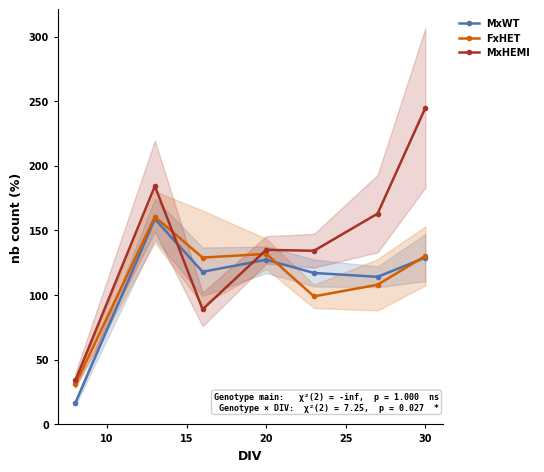


############################################################
# Network Burst Rate (Hz)
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_rate_hz ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        7.254    2     0.0266      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0266).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  0.859     0.3906     ns
  MxWT vs MxHEMI                -1.129     0.2589     ns
  FxHET vs MxHEMI               -1.751     0.0800     ns

  ── Fixed-effect coefficients (full

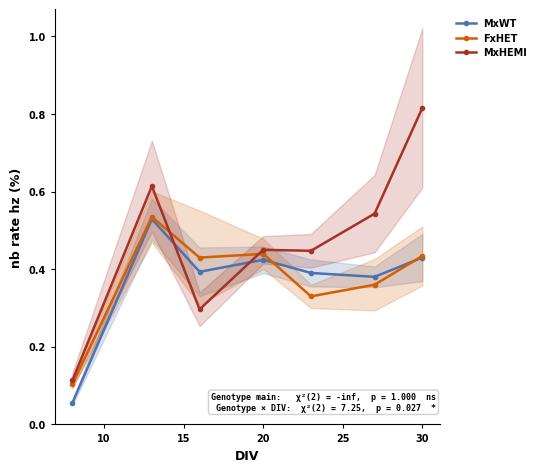


############################################################
# Mean Network Burst Duration (s)
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_duration_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        0.675    2     0.7136     ns

  ── Interpretation ───────────────────────────────────────────
  ✓ No significant genotype effect on Active Area.
    → Absolute-threshold QC is defensible.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  0.560     0.5757     ns
  MxWT vs MxHEMI                 1.763     0.0779     ns
  FxHET vs MxHEMI                1.249     0.2117     ns

  ── Fixed-effect coefficients (full model, ref=MxWT) ────────
                                                 Coef. Std.Err.      

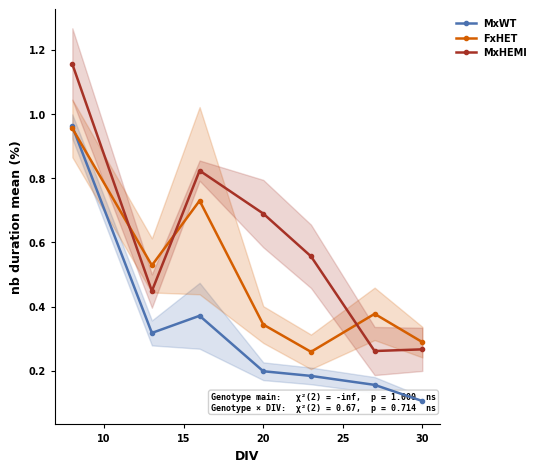


############################################################
# Mean Inter-Burst Interval (s)
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_ibi_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)       13.032    2     0.0015     **

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0015).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                 -3.847     0.0001    ***
  MxWT vs MxHEMI                -2.904     0.0037     **
  FxHET vs MxHEMI                0.231     0.8173     ns

  ── Fixed-effect coefficients (ful

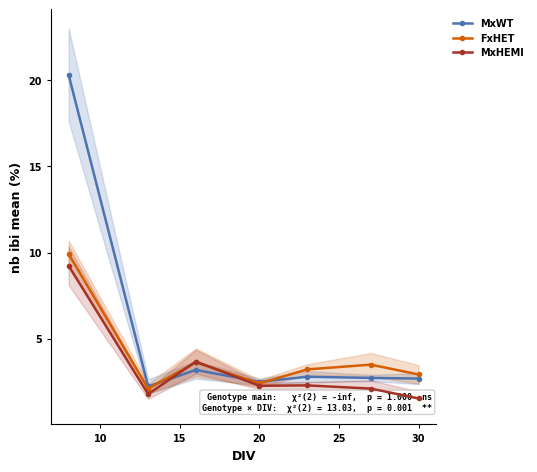


############################################################
# Mean Spikes per Network Burst
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_spikes_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        0.377    2     0.8281     ns

  ── Interpretation ───────────────────────────────────────────
  ✓ No significant genotype effect on Active Area.
    → Absolute-threshold QC is defensible.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  1.109     0.2676     ns
  MxWT vs MxHEMI                 0.539     0.5897     ns
  FxHET vs MxHEMI               -0.350     0.7262     ns

  ── Fixed-effect coefficients (full model, ref=MxWT) ────────
                                                   Coef.  Std.Err.     

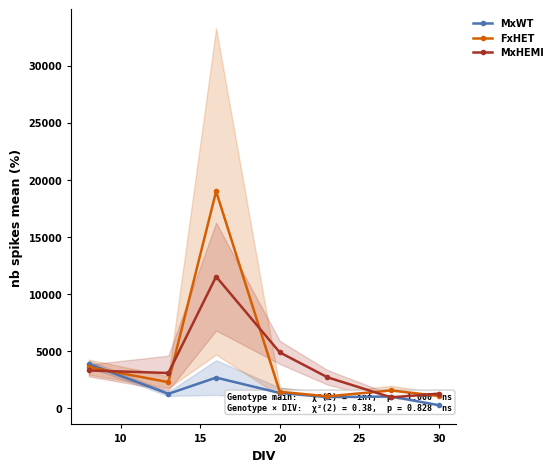


############################################################
# Mean Participation Fraction
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_participation_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        8.465    2     0.0145      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0145).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                 -1.468     0.1422     ns
  MxWT vs MxHEMI                 0.166     0.8685     ns
  FxHET vs MxHEMI                1.305     0.1920     ns

  ── Fixed-effect coeffic

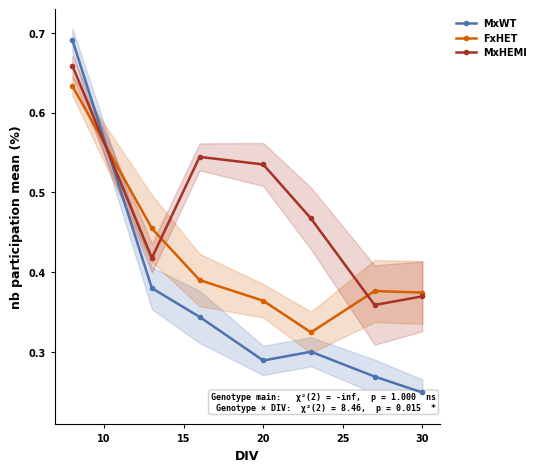


############################################################
# Mean Peak Population Firing Rate (Hz)
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_burst_peak_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        2.953    2     0.2284     ns

  ── Interpretation ───────────────────────────────────────────
  ✓ No significant genotype effect on Active Area.
    → Absolute-threshold QC is defensible.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  1.009     0.3129     ns
  MxWT vs MxHEMI                 0.179     0.8581     ns
  FxHET vs MxHEMI               -0.618     0.5369     ns

  ── Fixed-effect coefficients (full model, ref=MxWT) ────────
                                                   Coef. Std.Err.  

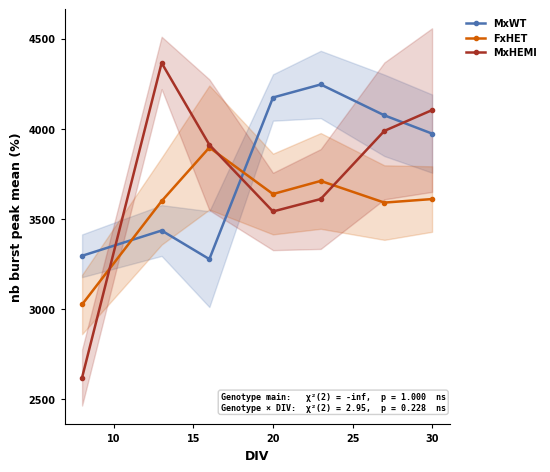


############################################################
# Mean Fragment Count per Burst
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_fragment_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        4.080    2     0.1300     ns

  ── Interpretation ───────────────────────────────────────────
  ✓ No significant genotype effect on Active Area.
    → Absolute-threshold QC is defensible.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                 -0.710     0.4776     ns
  MxWT vs MxHEMI                 0.828     0.4079     ns
  FxHET vs MxHEMI                1.346     0.1782     ns

  ── Fixed-effect coefficients (full model, ref=MxWT) ────────
                                                 Coef. Std.Err.      

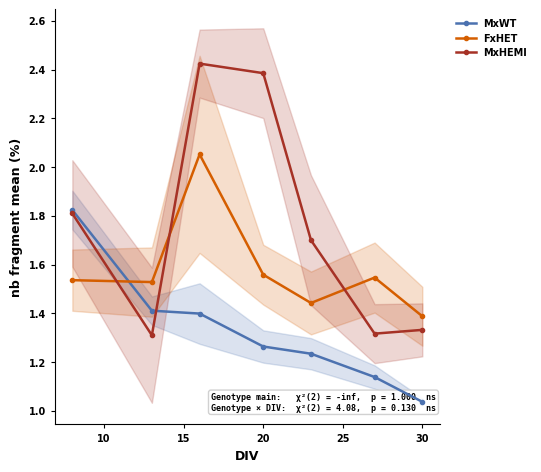


############################################################
# Mean Peak Participation Fraction
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: nb_peak_sync_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        6.182    2     0.0455      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0455).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  2.797     0.0052     **
  MxWT vs MxHEMI                 2.444     0.0145      *
  FxHET vs MxHEMI                0.156     0.8764     ns

  ── Fixed-effect coefficient

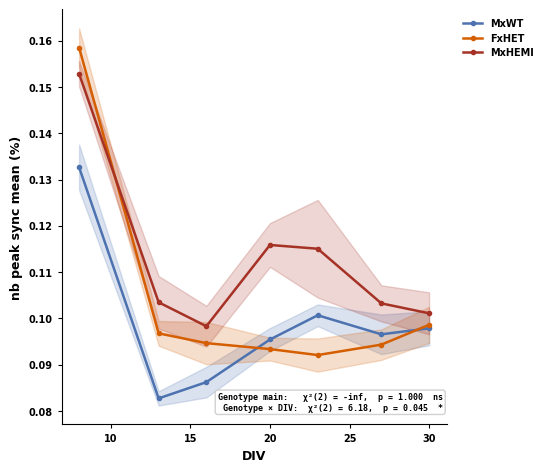


############################################################
# Burst Fragment Count
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/global/homes/m/mpatil1/.local/lib/python3.13/site-pa

LMM: bl_count ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        8.252    2     0.0161      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0161).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  0.613     0.5400     ns
  MxWT vs MxHEMI                -0.825     0.4096     ns
  FxHET vs MxHEMI               -1.267     0.2051     ns

  ── Fixed-effect coefficients (full m

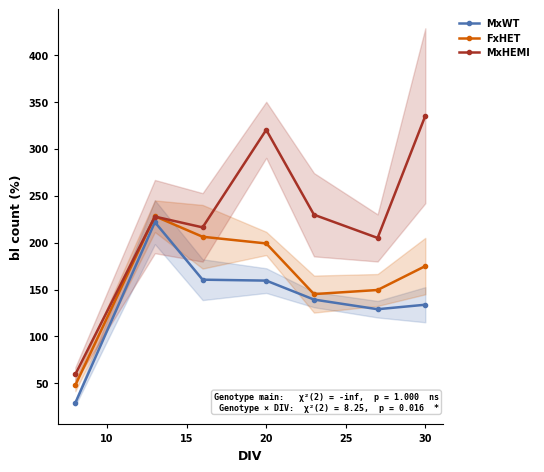


############################################################
# Burst Fragment Rate (Hz)
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: bl_rate_hz ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        8.268    2     0.0160      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0160).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  0.618     0.5367     ns
  MxWT vs MxHEMI                -0.825     0.4096     ns
  FxHET vs MxHEMI               -1.271     0.2037     ns

  ── Fixed-effect coefficients (full

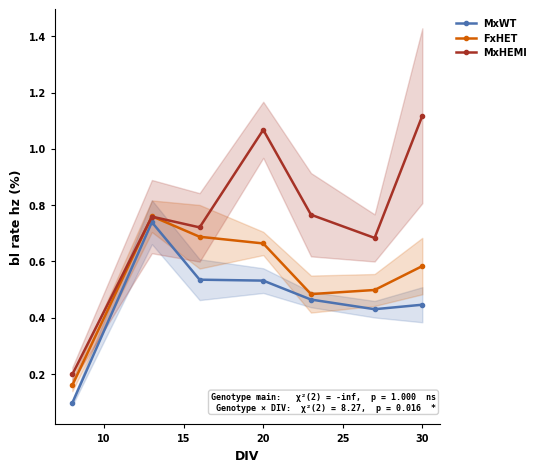


############################################################
# Mean Burst Fragment Duration (s)
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


LMM: bl_duration_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        0.194    2     0.9077     ns

  ── Interpretation ───────────────────────────────────────────
  ✓ No significant genotype effect on Active Area.
    → Absolute-threshold QC is defensible.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  1.275     0.2024     ns
  MxWT vs MxHEMI                 1.503     0.1328     ns
  FxHET vs MxHEMI                0.442     0.6586     ns

  ── Fixed-effect coefficients (full model, ref=MxWT) ────────
                                                 Coef. Std.Err.      

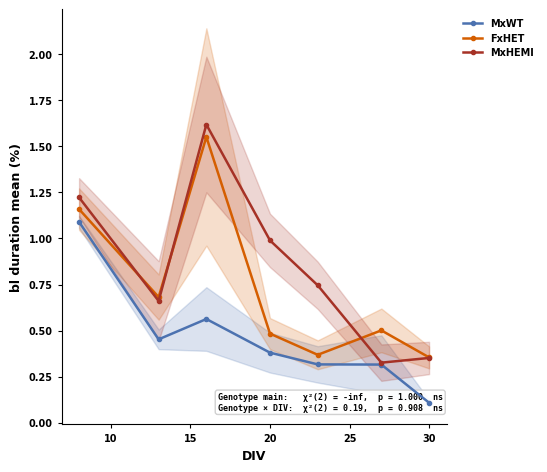


############################################################
# Mean Burst Fragment Participation
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_lin

LMM: bl_participation_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)            13.738    2     0.0010     **
  Genotype × DIV (trajectory)       11.150    2     0.0038     **

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0038).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                 -1.388     0.1652     ns
  MxWT vs MxHEMI                 0.023     0.9815     ns
  FxHET vs MxHEMI                1.105     0.2690     ns

  ── Fixed-effect coeffic

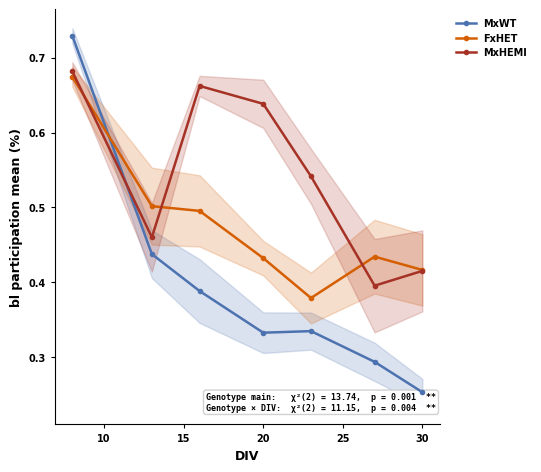


############################################################
# Superburst Count
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: sb_count ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        9.019    2     0.0110      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0110).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  0.755     0.4501     ns
  MxWT vs MxHEMI                -0.845     0.3982     ns
  FxHET vs MxHEMI               -1.665     0.0960     ns

  ── Fixed-effect coefficients (full m

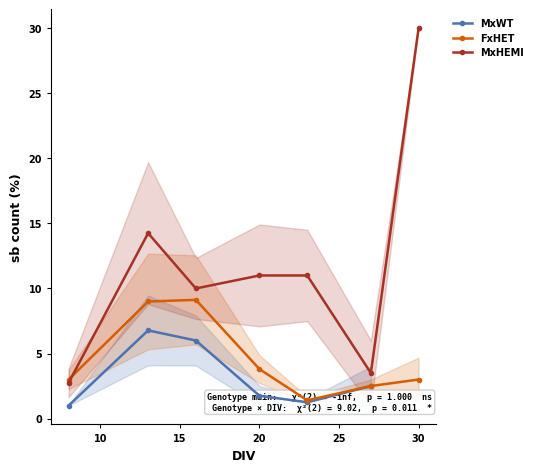


############################################################
# Superburst Rate (Hz)
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmod

LMM: sb_rate_hz ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        9.019    2     0.0110      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0110).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  0.755     0.4501     ns
  MxWT vs MxHEMI                -0.845     0.3981     ns
  FxHET vs MxHEMI               -1.665     0.0960     ns

  ── Fixed-effect coefficients (full

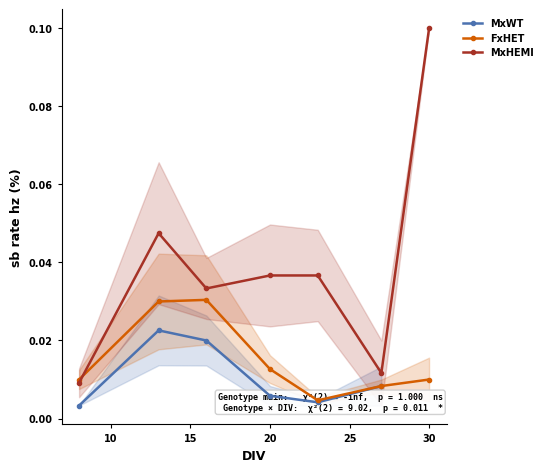


############################################################
# Mean Superburst Duration (s)
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_lin

LMM: sb_duration_mean ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)             4.161    2     0.1248     ns
  Genotype × DIV (trajectory)        6.516    2     0.0385      *

  ── Interpretation ───────────────────────────────────────────
  ✦ Trajectories DIVERGE over time (interaction p = 0.0385).
    Active Area differences are DIV-dependent.
    → Do NOT use an absolute threshold filter.
      Use within-genotype (MAD) QC only.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                  1.806     0.0710     ns
  MxWT vs MxHEMI                 0.757     0.4491     ns
  FxHET vs MxHEMI               -0.910     0.3630     ns

  ── Fixed-effect coefficients

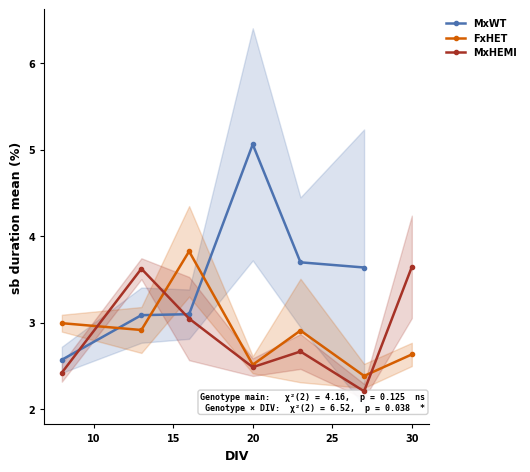


############################################################
# Number of Units
############################################################


/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/global/homes/m/mpatil1/.local/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


LMM: n_units ~ NeuronType * DIV + (1 | CHIP_WELL)
Reference: MxWT   |   n wells: 22

  Effect                                χ²   df          p       
  -------------------------------- -------  ---  ---------  -----
  Genotype (main effect)              -inf    2     1.0000     ns
  Genotype × DIV (trajectory)        1.928    2     0.3813     ns

  ── Interpretation ───────────────────────────────────────────
  ✓ No significant genotype effect on Active Area.
    → Absolute-threshold QC is defensible.

  ── Pairwise Wald tests (full model) ─────────────────────────
  Comparison                         z          p       
  ---------------------------- -------  ---------  -----
  MxWT vs FxHET                 -0.230     0.8184     ns
  MxWT vs MxHEMI                 0.167     0.8676     ns
  FxHET vs MxHEMI                0.339     0.7348     ns

  ── Fixed-effect coefficients (full model, ref=MxWT) ────────
                                                  Coef. Std.Err.       z  P>|z

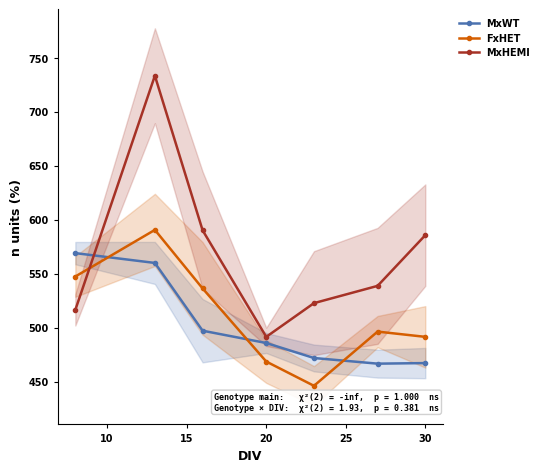


── LMM summary ──────────────────────────────────────────────────
               Metric  Main p Main sig  Interaction p Interaction sig
             nb_count  1.0000       ns         0.0266               *
           nb_rate_hz  1.0000       ns         0.0266               *
     nb_duration_mean  1.0000       ns         0.7136              ns
          nb_ibi_mean  1.0000       ns         0.0015              **
       nb_spikes_mean  1.0000       ns         0.8281              ns
nb_participation_mean  1.0000       ns         0.0145               *
   nb_burst_peak_mean  1.0000       ns         0.2284              ns
     nb_fragment_mean  1.0000       ns         0.1300              ns
    nb_peak_sync_mean  1.0000       ns         0.0455               *
             bl_count  1.0000       ns         0.0161               *
           bl_rate_hz  1.0000       ns         0.0160               *
     bl_duration_mean  1.0000       ns         0.9077              ns
bl_participation_mean  

In [7]:
# ── LMM: value ~ Genotype * DIV + (1 | CHIP_WELL) ────────────────────────────
# Two LRTs per metric: main genotype effect + genotype × DIV interaction.
lmm_results = {}

for col, ylabel in METRICS:
    if col not in network_assay_df.columns:
        print(f"[SKIP] {col}")
        continue
    print(f'\n{"#"*60}\n# {ylabel}\n{"#"*60}')
    try:
        fig, ax_data, ax_fit, lrt = test_genotype_lmm(
            network_assay_df,
            group_col='NeuronType', div_col='DIV', value_col=col,
            unit_col='CHIP_WELL', group_order=GROUP_ORDER, palette=PALETTE,
            figsize=(5.5, 5.0),
            save_path=os.path.join(FIGURE_DIR, f'{col}_lmm.svg'),
        )
        lmm_results[col] = lrt
        plt.show()
    except Exception as e:
        print(f"[ERROR] {col}: {e}")

# LMM summary table
rows = []
for col, lrt in lmm_results.items():
    rows.append({
        'Metric':          col,
        'Main p':          round(lrt['main']['p'], 4),
        'Main sig':        '***' if lrt['main']['p'] < 0.001 else '**' if lrt['main']['p'] < 0.01 else '*' if lrt['main']['p'] < 0.05 else 'ns',
        'Interaction p':   round(lrt['interaction']['p'], 4),
        'Interaction sig': '***' if lrt['interaction']['p'] < 0.001 else '**' if lrt['interaction']['p'] < 0.01 else '*' if lrt['interaction']['p'] < 0.05 else 'ns',
    })
print('\n── LMM summary ──────────────────────────────────────────────────')
print(pd.DataFrame(rows).to_string(index=False))

## KW → Wilcoxon → BH-FDR  +  trajectory + dot-plot panels


==================== STATS (KW + Wilcoxon, BH-FDR): nb_count ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=12.073 p=0.00239 → pairwise tests
  DIV 16: KW H=0.294 p=0.8633 → ns (no pairwise tests)
  DIV 23: KW H=3.571 p=0.1677 → ns (no pairwise tests)

  BH-FDR: 2/3 pairs significant (q < 0.05)


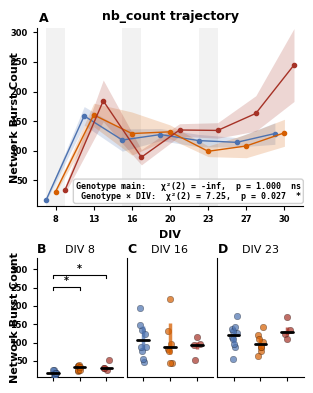

nb_count — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
   8  MxWT vs FxHET 0.010244   *
   8 MxWT vs MxHEMI 0.010814   *


==================== STATS (KW + Wilcoxon, BH-FDR): nb_rate_hz ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=13.019 p=0.001489 → pairwise tests
  DIV 16: KW H=0.294 p=0.8633 → ns (no pairwise tests)
  DIV 23: KW H=3.718 p=0.1558 → ns (no pairwise tests)

  BH-FDR: 2/3 pairs significant (q < 0.05)


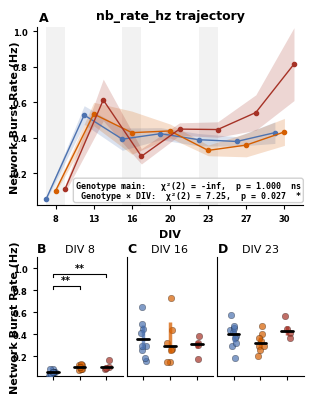

nb_rate_hz — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
   8  MxWT vs FxHET 0.007017  **
   8 MxWT vs MxHEMI 0.007017  **


==================== STATS (KW + Wilcoxon, BH-FDR): nb_duration_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=3.065 p=0.216 → ns (no pairwise tests)
  DIV 16: KW H=6.478 p=0.03921 → pairwise tests
  DIV 23: KW H=7.835 p=0.01989 → pairwise tests

  BH-FDR: 1/6 pairs significant (q < 0.05)


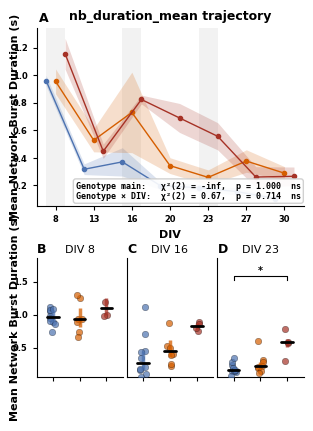

nb_duration_mean — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
  23 MxWT vs MxHEMI 0.043257   *


==================== STATS (KW + Wilcoxon, BH-FDR): nb_ibi_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=12.084 p=0.002377 → pairwise tests
  DIV 16: KW H=0.388 p=0.8238 → ns (no pairwise tests)
  DIV 23: KW H=3.625 p=0.1633 → ns (no pairwise tests)

  BH-FDR: 2/3 pairs significant (q < 0.05)


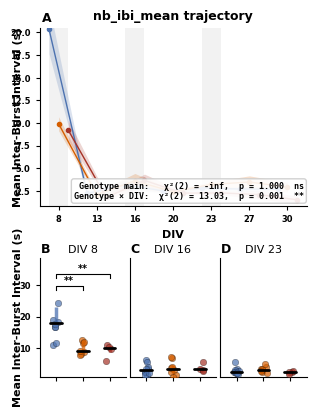

nb_ibi_mean — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
   8  MxWT vs FxHET 0.007017  **
   8 MxWT vs MxHEMI 0.007017  **


==================== STATS (KW + Wilcoxon, BH-FDR): nb_spikes_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=0.947 p=0.6227 → ns (no pairwise tests)
  DIV 16: KW H=7.689 p=0.0214 → pairwise tests
  DIV 23: KW H=6.184 p=0.0454 → pairwise tests

  BH-FDR: 0/6 pairs significant (q < 0.05)


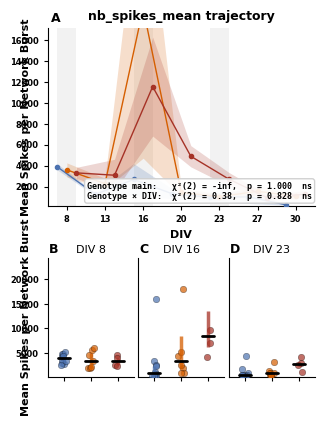

nb_spikes_mean — no significant pairs after FDR correction


==================== STATS (KW + Wilcoxon, BH-FDR): nb_participation_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=7.040 p=0.0296 → pairwise tests
  DIV 16: KW H=8.747 p=0.0126 → pairwise tests
  DIV 23: KW H=7.566 p=0.02276 → pairwise tests

  BH-FDR: 5/9 pairs significant (q < 0.05)


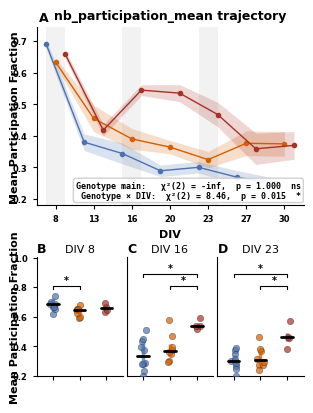

nb_participation_mean — significant pairs (q < 0.05):
 DIV      comparison    q_val Sig
   8   MxWT vs FxHET 0.033510   *
  16 FxHET vs MxHEMI 0.049047   *
  16  MxWT vs MxHEMI 0.032443   *
  23 FxHET vs MxHEMI 0.049047   *
  23  MxWT vs MxHEMI 0.032443   *


==================== STATS (KW + Wilcoxon, BH-FDR): nb_burst_peak_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=6.302 p=0.0428 → pairwise tests
  DIV 16: KW H=2.721 p=0.2565 → ns (no pairwise tests)
  DIV 23: KW H=4.619 p=0.0993 → ns (no pairwise tests)

  BH-FDR: 1/3 pairs significant (q < 0.05)


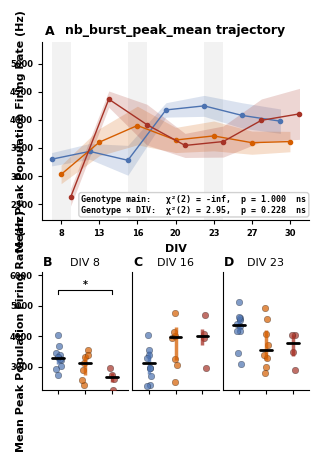

nb_burst_peak_mean — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
   8 MxWT vs MxHEMI 0.032728   *


==================== STATS (KW + Wilcoxon, BH-FDR): nb_fragment_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=3.637 p=0.1623 → ns (no pairwise tests)
  DIV 16: KW H=8.733 p=0.0127 → pairwise tests
  DIV 23: KW H=3.803 p=0.1494 → ns (no pairwise tests)

  BH-FDR: 1/3 pairs significant (q < 0.05)


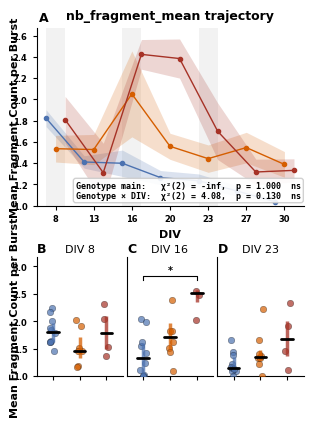

nb_fragment_mean — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
  16 MxWT vs MxHEMI 0.021629   *


==================== STATS (KW + Wilcoxon, BH-FDR): nb_peak_sync_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=11.467 p=0.003236 → pairwise tests
  DIV 16: KW H=5.683 p=0.05834 → ns (no pairwise tests)
  DIV 23: KW H=6.835 p=0.03279 → pairwise tests

  BH-FDR: 2/6 pairs significant (q < 0.05)


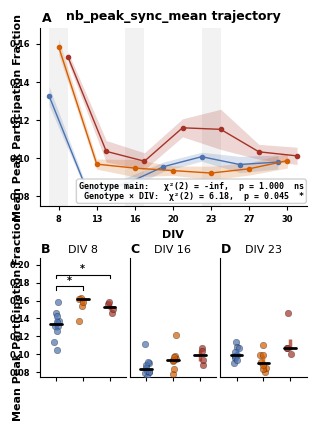

nb_peak_sync_mean — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
   8  MxWT vs FxHET 0.020489   *
   8 MxWT vs MxHEMI 0.048629   *


==================== STATS (KW + Wilcoxon, BH-FDR): bl_count ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=10.283 p=0.005848 → pairwise tests
  DIV 16: KW H=1.203 p=0.548 → ns (no pairwise tests)
  DIV 23: KW H=3.518 p=0.1722 → ns (no pairwise tests)

  BH-FDR: 2/3 pairs significant (q < 0.05)


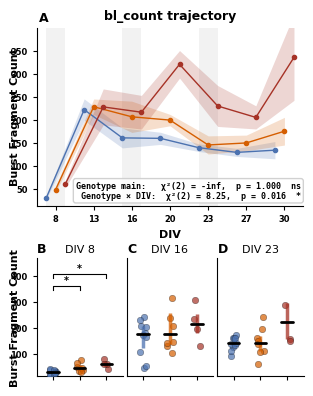

bl_count — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
   8  MxWT vs FxHET 0.025207   *
   8 MxWT vs MxHEMI 0.021629   *


==================== STATS (KW + Wilcoxon, BH-FDR): bl_rate_hz ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=10.427 p=0.005444 → pairwise tests
  DIV 16: KW H=1.176 p=0.5554 → ns (no pairwise tests)
  DIV 23: KW H=3.510 p=0.1729 → ns (no pairwise tests)

  BH-FDR: 2/3 pairs significant (q < 0.05)


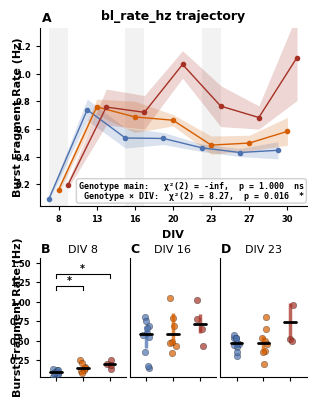

bl_rate_hz — significant pairs (q < 0.05):
 DIV     comparison    q_val Sig
   8  MxWT vs FxHET 0.022046   *
   8 MxWT vs MxHEMI 0.021629   *


==================== STATS (KW + Wilcoxon, BH-FDR): bl_duration_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=1.536 p=0.4639 → ns (no pairwise tests)
  DIV 16: KW H=7.502 p=0.02349 → pairwise tests
  DIV 23: KW H=6.328 p=0.04225 → pairwise tests

  BH-FDR: 0/6 pairs significant (q < 0.05)


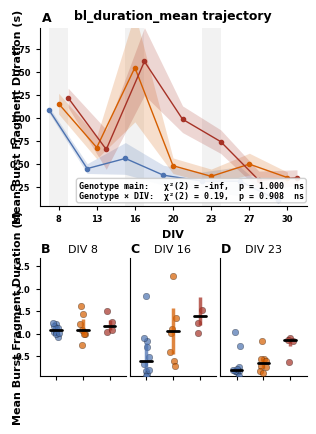

bl_duration_mean — no significant pairs after FDR correction


==================== STATS (KW + Wilcoxon, BH-FDR): bl_participation_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=10.060 p=0.006538 → pairwise tests
  DIV 16: KW H=8.825 p=0.01213 → pairwise tests
  DIV 23: KW H=8.747 p=0.0126 → pairwise tests

  BH-FDR: 5/9 pairs significant (q < 0.05)


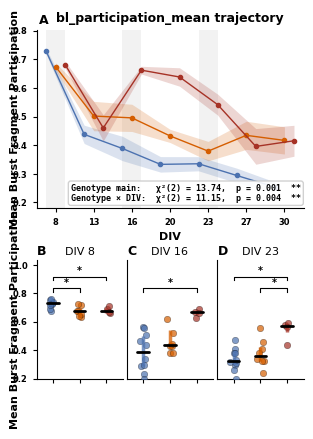

bl_participation_mean — significant pairs (q < 0.05):
 DIV      comparison    q_val Sig
   8   MxWT vs FxHET 0.021629   *
   8  MxWT vs MxHEMI 0.031351   *
  16  MxWT vs MxHEMI 0.021629   *
  23 FxHET vs MxHEMI 0.031351   *
  23  MxWT vs MxHEMI 0.021629   *


==================== STATS (KW + Wilcoxon, BH-FDR): sb_count ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=5.848 p=0.05371 → ns (no pairwise tests)
  DIV 16: KW H=0.781 p=0.6767 → ns (no pairwise tests)
  DIV 23: KW H=7.305 p=0.02593 → pairwise tests

  BH-FDR: 0/3 pairs significant (q < 0.05)


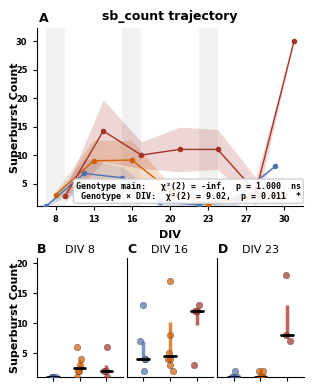

sb_count — no significant pairs after FDR correction


==================== STATS (KW + Wilcoxon, BH-FDR): sb_rate_hz ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=6.595 p=0.03697 → pairwise tests
  DIV 16: KW H=0.635 p=0.7279 → ns (no pairwise tests)
  DIV 23: KW H=6.369 p=0.04139 → pairwise tests

  BH-FDR: 0/6 pairs significant (q < 0.05)


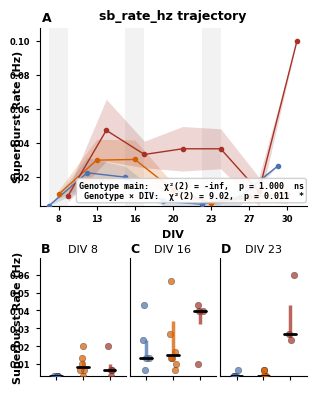

sb_rate_hz — no significant pairs after FDR correction


==================== STATS (KW + Wilcoxon, BH-FDR): sb_duration_mean ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=8.214 p=0.01645 → pairwise tests
  DIV 16: KW H=1.291 p=0.5244 → ns (no pairwise tests)
  DIV 23: KW H=2.368 p=0.3061 → ns (no pairwise tests)

  BH-FDR: 1/3 pairs significant (q < 0.05)


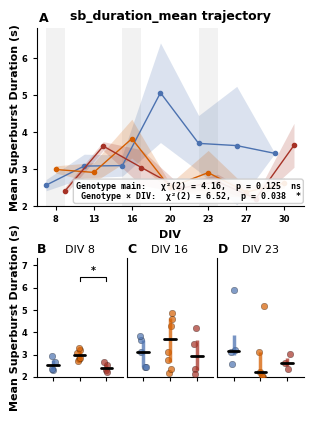

sb_duration_mean — significant pairs (q < 0.05):
 DIV      comparison    q_val Sig
   8 FxHET vs MxHEMI 0.031546   *


==================== STATS (KW + Wilcoxon, BH-FDR): n_units ====================
Selected timepoints: [8, 16, 23]  min_n=3
  DIV 8: KW H=4.864 p=0.08784 → ns (no pairwise tests)
  DIV 16: KW H=2.093 p=0.3511 → ns (no pairwise tests)
  DIV 23: KW H=1.930 p=0.3809 → ns (no pairwise tests)


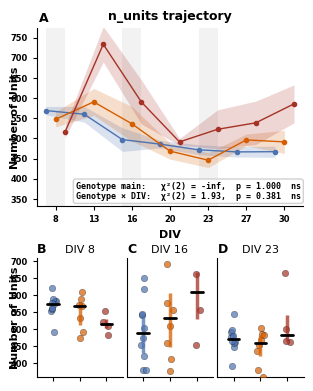

n_units — no significant pairs after FDR correction



In [8]:
# ── KW omnibus → pairwise Wilcoxon → BH-FDR + compact trajectory plot ────────
# Mirrors networkmetricsfigures.ipynb cell 2 exactly.
fdr_frames = {}

for col, ylabel in METRICS:
    if col not in network_assay_df.columns:
        print(f"[SKIP] {col}")
        continue
    try:
        stats = viz.calculate_stats_at_timepoints(
            network_assay_df, div_col='DIV', group_col='NeuronType', y=col,
            selected_divs=SELECTED_DIVS, group_order=GROUP_ORDER,
        )
        fdr_frames[col] = stats.assign(metric=col)

        fig, ax_traj, ax_dots = viz.plot_trajectory_with_dotplots(
            network_assay_df, div_col='DIV', group_col='NeuronType', y=col,
            selected_divs=SELECTED_DIVS, stats_df=stats,
            lmm_results=lmm_results.get(col),
            group_order=GROUP_ORDER, palette=PALETTE, ylabel=ylabel,
            figsize=(3.0, 4.2), height_ratios=(3, 2),
        )
        fig.savefig(os.path.join(FIGURE_DIR, f'{col}_FDR.svg'), format='svg', bbox_inches='tight')
        plt.show()

        sig = stats[stats['reject'] == True][['DIV', 'comparison', 'q_val', 'Sig']]
        if not sig.empty:
            print(f'{col} — significant pairs (q < 0.05):')
            print(sig.to_string(index=False))
        else:
            print(f'{col} — no significant pairs after FDR correction')
        print()
    except Exception as e:
        print(f"[ERROR] {col}: {e}")

In [9]:
# ── Export stats to text + Excel ──────────────────────────────────────────────
# Mirrors networkmetricsfigures.ipynb cell 3 exactly.
txt_path  = os.path.join(FIGURE_DIR, 'stats_report.txt')
xlsx_path = os.path.join(FIGURE_DIR, 'stats_report.xlsx')

lmm_summary = []
wald_frames = {}

with open(txt_path, 'w') as fout:
    fout.write("Statistical Report — Network Metrics\n")
    fout.write(f"Groups: {GROUP_ORDER}  |  Selected DIVs: {SELECTED_DIVS}\n")
    fout.write("=" * 70 + "\n\n")

    for col, ylabel in METRICS:
        if col not in network_assay_df.columns:
            continue
        fout.write(f"\n{'#'*70}\n# {ylabel}  [{col}]\n{'#'*70}\n\n")

        # LMM
        if col in lmm_results:
            lrt = lmm_results[col]
            lmm_summary.append({
                'Metric':         col,
                'ylabel':         ylabel,
                'Main χ²':        round(lrt['main']['chi2'], 3),
                'Main df':        lrt['main']['df'],
                'Main p':         round(lrt['main']['p'], 4),
                'Interaction χ²': round(lrt['interaction']['chi2'], 3),
                'Interaction df': lrt['interaction']['df'],
                'Interaction p':  round(lrt['interaction']['p'], 4),
            })
            if 'pairwise_wald' in lrt:
                wald_rows = [
                    {'comparison': f"{g1} vs {g2}", 'z': round(v['z'], 3), 'p': round(v['p'], 4)}
                    for (g1, g2), v in lrt['pairwise_wald'].items()
                ]
                wald_frames[col] = pd.DataFrame(wald_rows)
                fout.write("── LMM pairwise Wald ──\n")
                fout.write(wald_frames[col].to_string(index=False) + "\n\n")

        # KW / Wilcoxon / BH-FDR
        fout.write("── KW → Wilcoxon → BH-FDR ──\n")
        if col in fdr_frames:
            s = fdr_frames[col]
            fout.write(s[['DIV', 'comparison', 'KW_stat', 'KW_p',
                           'W_stat', 'raw_p', 'q_val', 'Sig',
                           'Grp1_Stats', 'Grp2_Stats', "Cohen's d"]
                        ].to_string(index=False) + "\n")

print(f"Text report  → {txt_path}")

with pd.ExcelWriter(xlsx_path, engine='openpyxl') as writer:
    if lmm_summary:
        pd.DataFrame(lmm_summary).to_excel(writer, sheet_name='LMM_summary', index=False)
    for col, df_s in fdr_frames.items():
        df_s.to_excel(writer, sheet_name=col[:31], index=False)
    for col, df_w in wald_frames.items():
        df_w.to_excel(writer, sheet_name=(col[:27] + '_wald')[:31], index=False)

print(f"Excel report → {xlsx_path}")

Text report  → /pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/CDKL5_T1/figures/stats_report.txt
Excel report → /pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/CDKL5_T1/figures/stats_report.xlsx
